# part a netflix exploratory data analysis

this notebook follows understand, inspect, clean, explore, interpret.
all text is simple lowercase with a few typos.
run cells from top to bottom.

In [1]:
# import tools for tables math and plots
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# clean plot style
plt.style.use("ggplot")

In [2]:
# read the netflix csv
df = pd.read_csv("netflix_titles.csv")

# print shape and sample rows
print("shape:", df.shape)
display(df.head(5))

# print column data types
print("\ncolumn dtypes:")
print(df.dtypes)

shape: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...



column dtypes:
show_id           str
type              str
title             str
director          str
cast              str
country           str
date_added        str
release_year    int64
rating            str
duration          str
listed_in         str
description       str
dtype: object


## a1 dataset understandig

one row is one netflix title, either movie or tv show.

### variable role table

| column | type | role note |
|---|---|---|
| show_id | identifier | unique id for each title |
| type | categorical | movie or tv show |
| title | text | title name |
| director | categorical (multi person) | director, often missing for tv shows |
| cast | multi valued categorical | actors, many values in one cell |
| country | multi valued categorical | production countries |
| date_added | date | date added to netflix |
| release_year | numerical | release year |
| rating | categorical | maturity rating, with a few bad values |
| duration | mixed | minutes for movies, seasons for tv shows |
| listed_in | multi valued categorical | genres |
| description | text | short summary |

most important are type, country, date_added, release_year, rating, duration, and listed_in.
text columns are useful for reading but not math.

## a2 data quality assement

we check missing values, duplicates, types, category consistency, suspicious values, and outliars.
evidence is printed by code below.

In [3]:
# count missing values by column
missing = df.isna().sum().sort_values(ascending=False)

# show as percent table
missing_pct = (missing / len(df) * 100).round(2)
quality_missing = pd.DataFrame({"missing": missing, "percent": missing_pct})
display(quality_missing)

,missing,percent
director,2634,29.91
country,831,9.44
cast,825,9.37
date_added,10,0.11
rating,4,0.05
duration,3,0.03
show_id,0,0.00
type,0,0.00
title,0,0.00
release_year,0,0.00


most missing values are in director, cast, and country.
this seems meaningful, not random.
tv shows often have no single director.
only ten titles have missing date_added.

In [4]:
# check full row duplicates
print("full-row duplicates:", df.duplicated().sum())

# check duplicate ids and titles
print("duplicate show_id:", df.show_id.duplicated().sum())
print("duplicate title:", df.title.duplicated().sum())

full-row duplicates: 0
duplicate show_id: 0
duplicate title: 0


no full row duplicates, and no duplicate ids or titles found.
this dataset is already unique by title.

In [5]:
# strip spaces and parse dates
raw_dates = pd.to_datetime(df["date_added"], errors="coerce", format="%B %d, %Y")
clean_dates = pd.to_datetime(df["date_added"].astype(str).str.strip(), errors="coerce", format="%B %d, %Y")
print("raw date parse failures:", raw_dates.isna().sum())
print("after strip failures:", clean_dates.isna().sum())

# show rating counts including bad values
print("\nrating value counts (bad values included):")
print(df["rating"].value_counts(dropna=False))

# show basic year and missing duration
print("\nduration missing:", df["duration"].isna().sum())
print("release year range:", df["release_year"].min(), "to", df["release_year"].max())

raw date parse failures: 98
after strip failures: 10

rating value counts (bad values included):
rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NaN            4
NC-17          3
UR             3
74 min         1
84 min         1
66 min         1
Name: count, dtype: int64

duration missing: 3
release year range: 1925 to 2021


country names are fine but stored as comma strings in one cell.
date_added has hidden leading spaces.
rating has three misplaced durations called 66 min, 74 min, and 84 min.
duration has three missing values that belong to those rows.

In [6]:
# split country cells into tokens
raw_country_tokens = df["country"].dropna().astype(str).str.split(",").explode().str.strip()

# count distinct country tokens
print("distinct country tokens after strip:", raw_country_tokens.nunique())
print("top country tokens:")
print(raw_country_tokens.value_counts().head(10))

# split genre cells
raw_genre_tokens = df["listed_in"].astype(str).str.split(",").explode().str.strip()
print("\ndistinct genre tokens:", raw_genre_tokens.nunique())

distinct country tokens after strip: 123
top country tokens:
country
United States     3690
India             1046
United Kingdom     806
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64

distinct genre tokens: 42


movie minutes min max mean median:
min         3.00
max       312.00
mean       99.58
median     98.00
Name: duration, dtype: float64
iqr bounds: (46.5, 154.5)


/tmp/ipykernel_978424/1055088945.py:17: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(movie_minutes_raw.dropna(), vert=False)


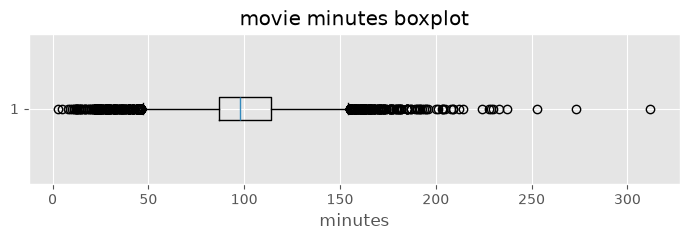


release year iqr bounds: (2004.0, 2028.0)
titles before lower bound: 719

tv season counts:
0
1.0     1793
2.0      425
3.0      199
4.0       95
5.0       65
6.0       33
7.0       23
8.0       17
9.0        9
10.0       7
11.0       2
12.0       2
13.0       3
15.0       2
17.0       1
Name: count, dtype: int64
season count iqr bounds: (-0.5, 3.5)


In [7]:
# iqr helper for outlier review
def iqr_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

# movie minutes summary and bounds
movie_rows = df[df["type"] == "Movie"].copy()
movie_minutes_raw = movie_rows["duration"].astype(str).str.replace(" min", "", regex=False)
movie_minutes_raw = pd.to_numeric(movie_minutes_raw, errors="coerce")
print("movie minutes min max mean median:")
print(movie_minutes_raw.agg(["min", "max", "mean", "median"]).round(2))
print("iqr bounds:", iqr_bounds(movie_minutes_raw.dropna()))

# plot movie minute outliers
plt.figure(figsize=(7, 2.5))
plt.boxplot(movie_minutes_raw.dropna(), vert=False)
plt.title("movie minutes boxplot")
plt.xlabel("minutes")
plt.tight_layout()
plt.show()

# release year bounds
year_bounds = iqr_bounds(df["release_year"])
print("\nrelease year iqr bounds:", year_bounds)
print("titles before lower bound:", (df["release_year"] < year_bounds[0]).sum())

# tv season summary
tv_rows = df[df["type"] == "TV Show"].copy()
tv_seasons = tv_rows["duration"].astype(str).str.extract(r"(\d+)")[0].astype(float)
print("\ntv season counts:")
print(tv_seasons.value_counts().sort_index())
print("season count iqr bounds:", iqr_bounds(tv_seasons.dropna()))

iqr flags many short movies and release years before 2004.
some values are extreme, like movies over 300 minutes and one 17 season show.
i keep them because they are real catalog titles, not errors.
i only correct clear mislabeled rows.

## a3 data cleaning

| problem | how found | decision | justification |
|---|---|---|---|
| missing director | value counts | fill unknown | many tv shows have no credited director |
| missing cast country | value counts | fill unknown | keeps rows for analysis and avoids false precision |
| missing date_added | isna check | leave missing | real missing date, not invented |
| bad rating | value counts | move minute values then unknown | rating column contained minute values by mistake |
| missing duration | duration isna | fill from misplaced rating | those rows had duration hiding in rating |
| mixed duration | inspection | split into movie_minutes season_count | minutes and seasons are different units |
| multi valued fields | comma strings | keep strings, count tokens | multi valued fields are not single labels |
| leading spaces | datetime parse | strip before parse | hidden whitespace caused parse failures |

In [8]:
# start from raw copy
netflix = df.copy()

# strip main text and categorical fields
for col in ["title", "director", "cast", "country", "listed_in", "type", "rating"]:
    netflix[col] = netflix[col].astype(str).str.strip()
    netflix.loc[netflix[col].isin(["nan", "None"]), col] = np.nan

# count tokens before filling
def count_tokens(x):
    if pd.isna(x):
        return 0
    return len([t for t in str(x).split(",") if t.strip()])

netflix["num_countries"] = netflix["country"].map(count_tokens)
netflix["num_genres"] = netflix["listed_in"].map(count_tokens)

# fix misplaced rating and duration rows
bad_rating_mask = netflix["rating"].astype(str).str.endswith("min")
netflix.loc[bad_rating_mask, "duration"] = netflix.loc[bad_rating_mask, "rating"]
netflix.loc[bad_rating_mask, "rating"] = "Unknown"
netflix.loc[netflix["rating"].isna(), "rating"] = "Unknown"

# fill simple categoricals
netflix["director"] = netflix["director"].fillna("Unknown")
netflix["cast"] = netflix["cast"].fillna("Unknown")
netflix["country"] = netflix["country"].fillna("Unknown")

# parse dates
netflix["date_added"] = pd.to_datetime(netflix["date_added"].astype(str).str.strip(), errors="coerce", format="%B %d, %Y")

# split mixed duration
duration_number = netflix["duration"].astype(str).str.extract(r"(\d+)")[0].astype(float)
is_movie = netflix["type"].eq("Movie")
netflix["movie_minutes"] = np.where(is_movie, duration_number, np.nan)
netflix["season_count"] = np.where(~is_movie, duration_number, np.nan)

# derived variables
netflix["year_added"] = netflix["date_added"].dt.year
netflix["content_age"] = netflix["year_added"] - netflix["release_year"]

# print results
print("cleaned shape:", netflix.shape)
print("remaining missing:")
print(netflix.isna().sum())
display(netflix[["type", "country", "date_added", "movie_minutes", "season_count", "num_countries", "num_genres", "year_added", "content_age"]].head())

cleaned shape: (8807, 18)
remaining missing:
show_id             0
type                0
title               0
director            0
cast                0
country             0
date_added         10
release_year        0
rating              0
duration            0
listed_in           0
description         0
num_countries       0
num_genres          0
movie_minutes    2676
season_count     6131
year_added         10
content_age        10
dtype: int64


,type,country,date_added,movie_minutes,season_count,num_countries,num_genres,year_added,content_age
0,Movie,United States,2021-09-25,90.0,NaN,1,1,2021.0,1.0
1,TV Show,South Africa,2021-09-24,NaN,2.0,1,3,2021.0,0.0
2,TV Show,Unknown,2021-09-24,NaN,1.0,0,3,2021.0,0.0
3,TV Show,Unknown,2021-09-24,NaN,1.0,0,2,2021.0,0.0
4,TV Show,India,2021-09-24,NaN,2.0,1,3,2021.0,0.0


In [9]:
# here we save the file
clean_path = "23l_0771_a2_netflix_cleaned.csv"
netflix.to_csv(clean_path, index=False)
print("saved:", clean_path)

saved: 23l_0771_a2_netflix_cleaned.csv


derived variables are useful later.

num_countries shows how many countries are linked.
num_genres shows how many genres are linked.
movie_minutes is real movie length.
season_count is tv show length.
year_added is year added to netflix.
content_age shows gap between release and addition.

## a4 univariate eda

i use bar charts for categories, histograms for numeric variables, and boxplots for spread and outliars.
counts and simple centre spread stats support charts.

content type counts:
type
Movie      6131
TV Show    2676
Name: count, dtype: int64


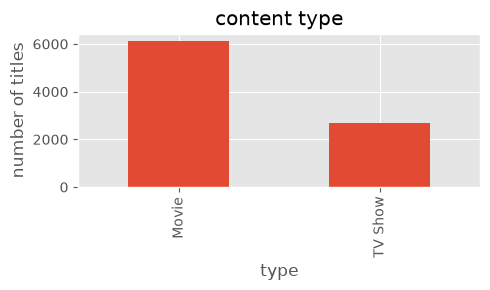


rating counts:
rating
TV-MA      3207
TV-14      2160
TV-PG       863
R           799
PG-13       490
TV-Y7       334
TV-Y        307
PG          287
TV-G        220
NR           80
G            41
Unknown       7
Name: count, dtype: int64


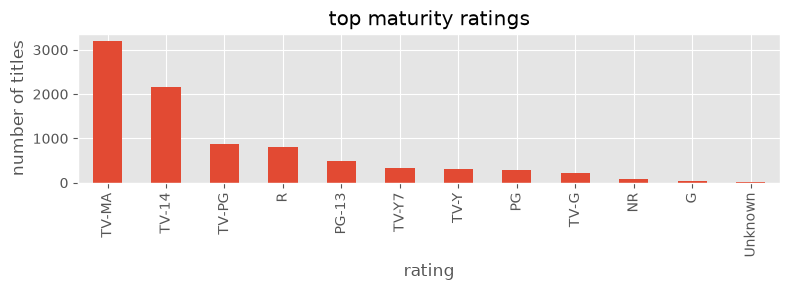

In [10]:
# type counts and bar chart
print("content type counts:")
print(netflix["type"].value_counts())
netflix["type"].value_counts().plot(kind="bar", figsize=(5, 3), title="content type")
plt.ylabel("number of titles")
plt.tight_layout()
plt.show()

# rating counts and bar chart
print("\nrating counts:")
print(netflix["rating"].value_counts().head(12))
netflix["rating"].value_counts().head(12).plot(kind="bar", figsize=(8, 3), title="top maturity ratings")
plt.ylabel("number of titles")
plt.tight_layout()
plt.show()

release year summary:
count    8807.00
mean     2014.18
std         8.82
min      1925.00
25%      2013.00
50%      2017.00
75%      2019.00
max      2021.00
Name: release_year, dtype: float64


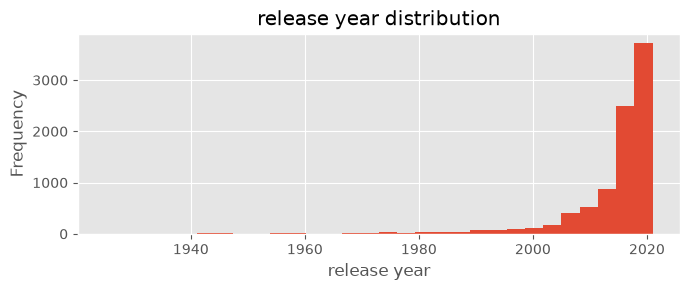

In [11]:
# release year summary and histogram
print("release year summary:")
print(netflix["release_year"].describe().round(2))
netflix["release_year"].plot(kind="hist", bins=30, figsize=(7, 3), title="release year distribution")
plt.xlabel("release year")
plt.tight_layout()
plt.show()

movie minutes summary:
count    6131.00
mean       99.56
std        28.29
min         3.00
25%        87.00
50%        98.00
75%       114.00
max       312.00
Name: movie_minutes, dtype: float64


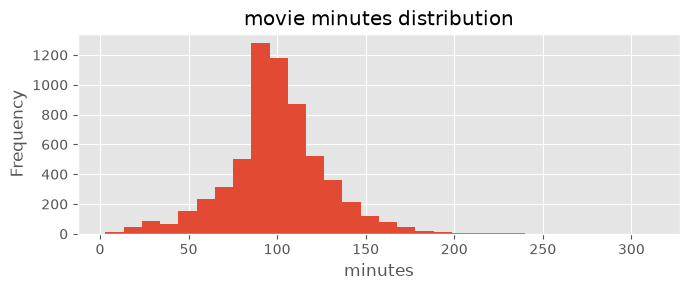

In [12]:
# movie minute summary and histogram
movie_only = netflix[netflix["type"] == "Movie"]
print("movie minutes summary:")
print(movie_only["movie_minutes"].describe().round(2))
movie_only["movie_minutes"].plot(kind="hist", bins=30, figsize=(7, 3), title="movie minutes distribution")
plt.xlabel("minutes")
plt.tight_layout()
plt.show()

season count summary:
count    2676.00
mean        1.76
std         1.58
min         1.00
25%         1.00
50%         1.00
75%         2.00
max        17.00
Name: season_count, dtype: float64


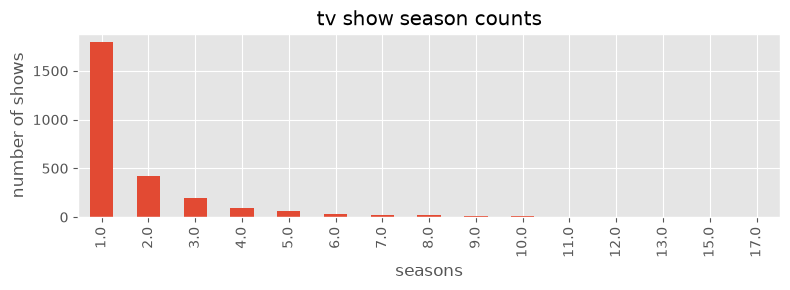

In [13]:
# season count summary and bar
tv_only = netflix[netflix["type"] == "TV Show"]
print("season count summary:")
print(tv_only["season_count"].describe().round(2))
tv_only["season_count"].value_counts().sort_index().plot(kind="bar", figsize=(8, 3), title="tv show season counts")
plt.xlabel("seasons")
plt.ylabel("number of shows")
plt.tight_layout()
plt.show()

top 10 country tokens:
country
United States     3690
India             1046
Unknown            831
United Kingdom     806
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Name: count, dtype: int64


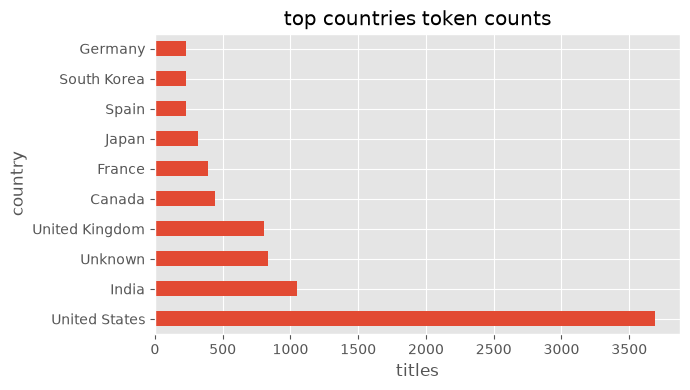


top 12 genres:
listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
TV Comedies                  581
Thrillers                    577
Name: count, dtype: int64


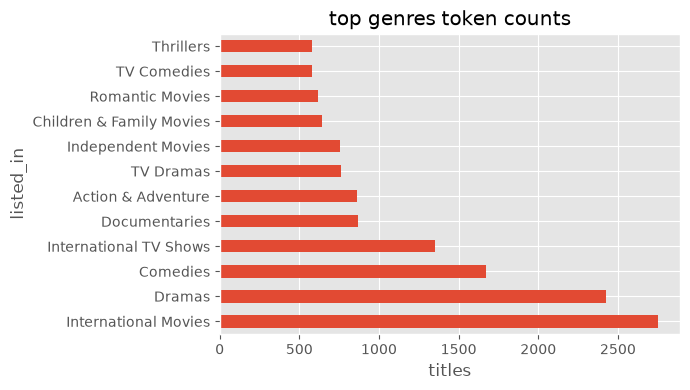

In [14]:
# country token counts and plot
country_counts = netflix["country"].str.split(",").explode().str.strip().value_counts().head(10)
print("top 10 country tokens:")
print(country_counts)
country_counts.plot(kind="barh", figsize=(7, 4), title="top countries token counts")
plt.xlabel("titles")
plt.tight_layout()
plt.show()

# genre token counts and plot
genre_counts = netflix["listed_in"].str.split(",").explode().str.strip().value_counts().head(12)
print("\ntop 12 genres:")
print(genre_counts)
genre_counts.plot(kind="barh", figsize=(7, 4), title="top genres token counts")
plt.xlabel("titles")
plt.tight_layout()
plt.show()

## a5 bivariate eda

we cover numerical-numerical, numerical-categorical, and categorical-categorical pairs.

In [15]:
# correlations for selected numericals
pair = netflix[["release_year", "movie_minutes", "season_count", "num_countries", "num_genres", "content_age"]].copy()
print("correlations selected numerical:")
print(pair.corr().round(2))

correlations selected numerical:
               release_year  movie_minutes  season_count  num_countries  \
release_year           1.00          -0.21         -0.09          -0.07   
movie_minutes         -0.21           1.00           NaN           0.09   
season_count          -0.09            NaN          1.00           0.12   
num_countries         -0.07           0.09          0.12           1.00   
num_genres            -0.04           0.41         -0.08           0.01   
content_age           -0.98           0.22          0.10           0.06   

               num_genres  content_age  
release_year        -0.04        -0.98  
movie_minutes        0.41         0.22  
season_count        -0.08         0.10  
num_countries        0.01         0.06  
num_genres           1.00         0.05  
content_age          0.05         1.00  


type vs rating counts:


rating,G,NC-17,NR,PG,PG-13,R,TV-14,TV-G,TV-MA,TV-PG,TV-Y,TV-Y7,TV-Y7-FV,UR,Unknown
type,,,,,,,,,,,,,,,
Movie,41,3,75,287,490,797,1427,126,2062,540,131,139,5,3,5
TV Show,0,0,5,0,0,2,733,94,1145,323,176,195,1,0,2


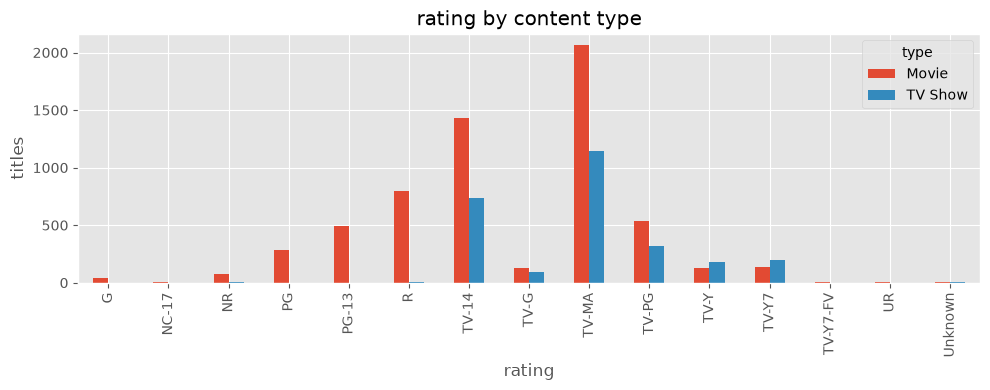

In [16]:
# type vs rating cross table and chart
rating_type = pd.crosstab(netflix["type"], netflix["rating"])
print("type vs rating counts:")
display(rating_type)
rating_type.T.plot(kind="bar", figsize=(10, 4), title="rating by content type")
plt.ylabel("titles")
plt.tight_layout()
plt.show()

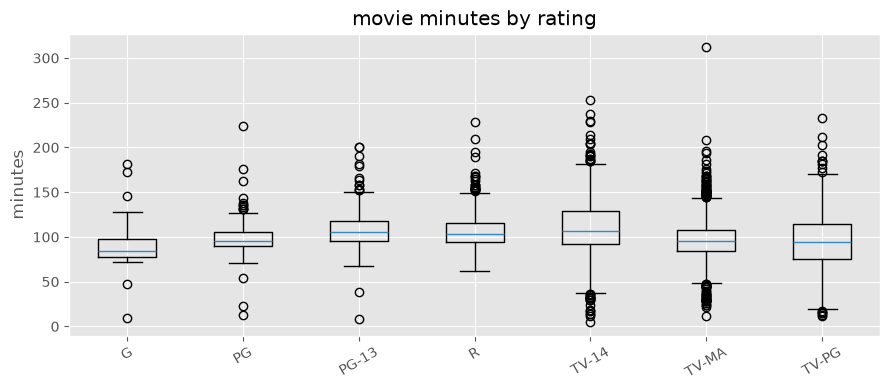

In [17]:
# movie minutes by rating boxplot
ratings_to_show = ["G", "PG", "PG-13", "R", "TV-14", "TV-MA", "TV-PG"]
plot_data = [movie_only[movie_only["rating"] == r]["movie_minutes"].dropna() for r in ratings_to_show]
plt.figure(figsize=(9, 4))
plt.boxplot(plot_data, tick_labels=ratings_to_show)
plt.title("movie minutes by rating")
plt.ylabel("minutes")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

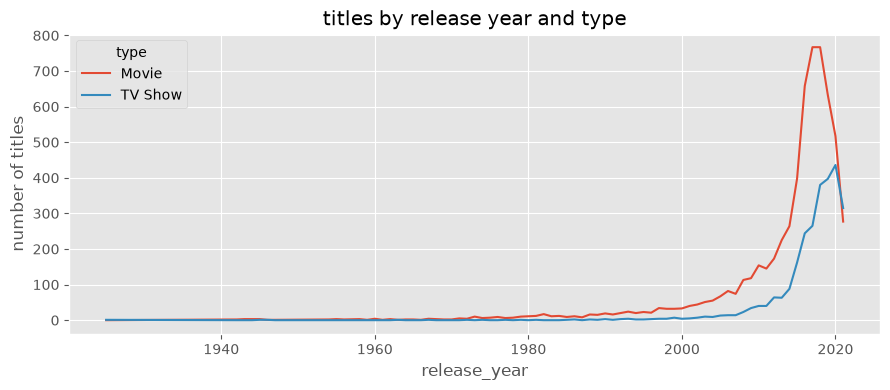

In [18]:
# type vs release year chart
year_type = pd.crosstab(netflix["release_year"], netflix["type"])
year_type.plot(figsize=(9, 4), title="titles by release year and type")
plt.ylabel("number of titles")
plt.tight_layout()
plt.show()

## a6 multivariate eda

here we check whether a pattern changes when a third variable is added.

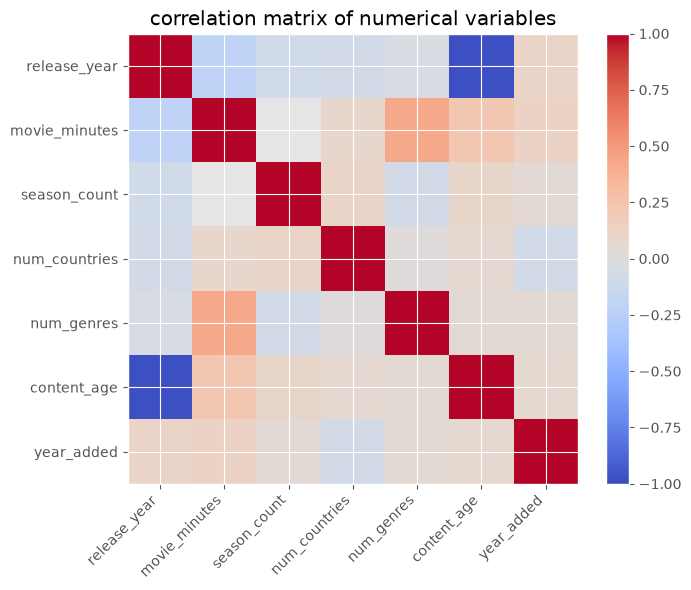

In [19]:
# correlation matrix chart
num_cols = ["release_year", "movie_minutes", "season_count", "num_countries", "num_genres", "content_age", "year_added"]
corr = netflix[num_cols].corr()
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols)))
ax.set_xticklabels(num_cols, rotation=45, ha="right")
ax.set_yticks(range(len(num_cols)))
ax.set_yticklabels(num_cols)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
ax.set_title("correlation matrix of numerical variables")
plt.tight_layout()
plt.show()

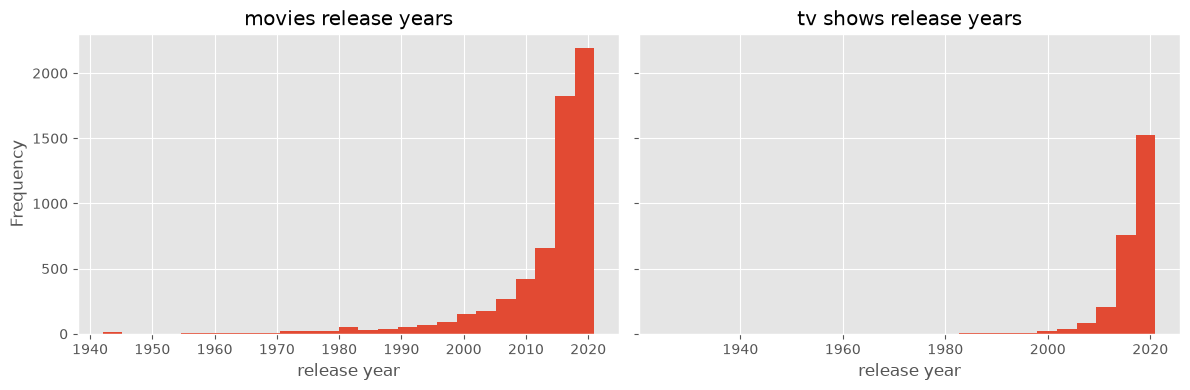

In [20]:
# faceted release years for movies and shows
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
netflix[netflix["type"] == "Movie"]["release_year"].plot(kind="hist", bins=25, ax=axes[0], title="movies release years")
netflix[netflix["type"] == "TV Show"]["release_year"].plot(kind="hist", bins=25, ax=axes[1], title="tv shows release years")
axes[0].set_xlabel("release year")
axes[1].set_xlabel("release year")
plt.tight_layout()
plt.show()

           country                     genre  count
0    United States                    Dramas    835
1    United States                  Comedies    680
2    United States             Documentaries    512
3    United States        Action & Adventure    404
4    United States        Independent Movies    390
5            India      International Movies    864
6            India                    Dramas    662
7            India                  Comedies    323
8            India        Independent Movies    167
9            India        Action & Adventure    137
10  United Kingdom          British TV Shows    225
11  United Kingdom                    Dramas    197
12  United Kingdom      International Movies    170
13  United Kingdom    International TV Shows    128
14  United Kingdom             Documentaries    128
15          Canada                  Comedies     94
16          Canada                    Dramas     82
17          Canada  Children & Family Movies     80
18          

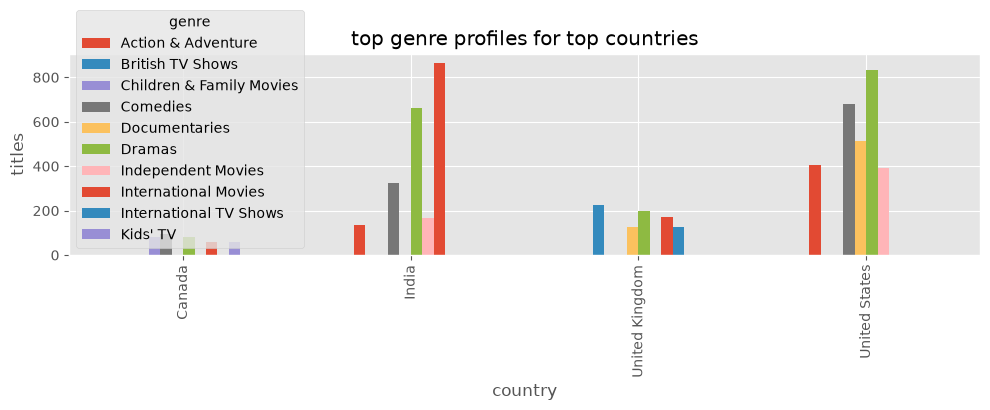

In [21]:
# genre profiles for top countries
top_countries = netflix["country"].str.split(",").explode().str.strip().value_counts().head(6).index.tolist()
top_countries = [c for c in top_countries if c != "Unknown"][:4]
rows = []
for c in top_countries:
    mask = netflix["country"].str.contains(c, regex=False)
    exploded = netflix[mask]["listed_in"].str.split(",").explode().str.strip()
    counts = exploded.value_counts().head(5)
    for genre, count in counts.items():
        rows.append({"country": c, "genre": genre, "count": count})
profile = pd.DataFrame(rows)
print(profile)
pivot = profile.pivot_table(index="country", columns="genre", values="count", fill_value=0)
pivot.plot(kind="bar", figsize=(10, 4), title="top genre profiles for top countries")
plt.ylabel("titles")
plt.tight_layout()
plt.show()

## a7 netflix specific analytical questions

question 1 how has the mix of movies and tv shows changed over time

movie share is high in older release years.
for titles added after 2018, the tv share among added titles is higher.
so mix moved toward tv shows.
data shows this shift but cannot explain business reason.

added mix by year last 6 years:


type,Movie,TV Show
year_added,,
2016.0,253,176
2017.0,839,349
2018.0,1237,412
2019.0,1424,592
2020.0,1284,595
2021.0,993,505


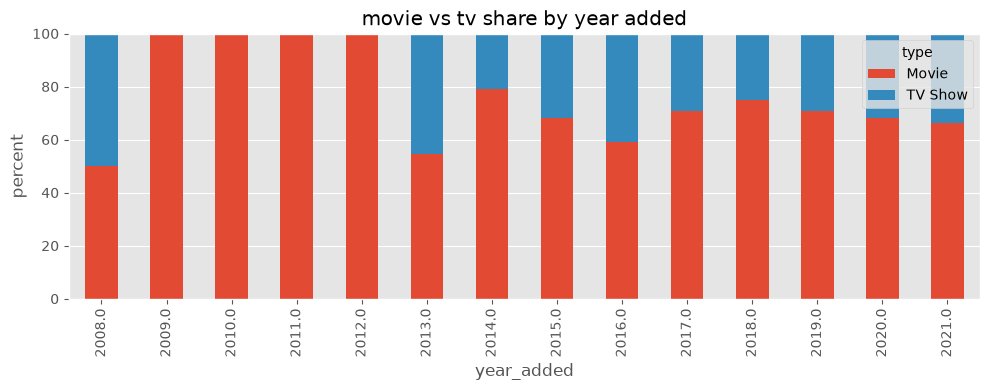

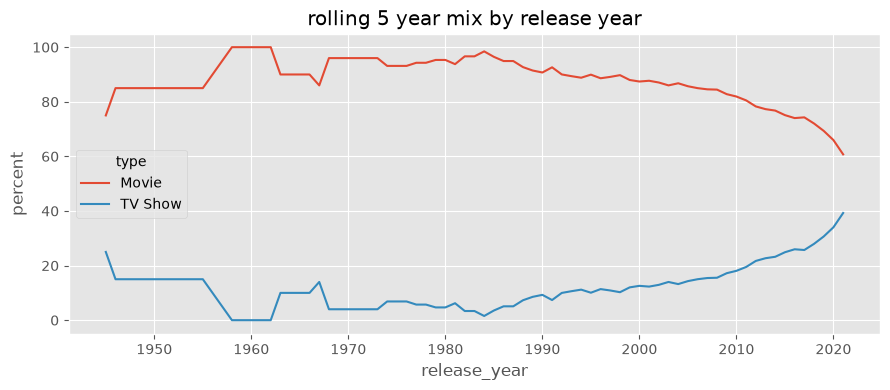

In [22]:
# added mix by year counts
mix = pd.crosstab(netflix["year_added"], netflix["type"])
print("added mix by year last 6 years:")
display(mix.tail(6))

# stacked percent chart
mix_pct = mix.div(mix.sum(axis=1), axis=0) * 100
mix_pct.plot(kind="bar", stacked=True, figsize=(10, 4), title="movie vs tv share by year added")
plt.ylabel("percent")
plt.tight_layout()
plt.show()

# rolling release year mix
mix_release = pd.crosstab(netflix["release_year"], netflix["type"])
mix_release_pct = mix_release.div(mix_release.sum(axis=1), axis=0) * 100
mix_release_pct.rolling(5).mean().plot(figsize=(9, 4), title="rolling 5 year mix by release year")
plt.ylabel("percent")
plt.tight_layout()
plt.show()

question 2 gap between release year and date added

most titles are added within a few years after release.
median gap about one year.
smaller group has very large gaps.
this suggests catalog mixes recent releases with older library titles.

content age summary:
count    8797.00
mean        4.69
std         8.79
min        -3.00
25%         0.00
50%         1.00
75%         5.00
max        93.00
dtype: float64
negative gaps (added before release year): 14


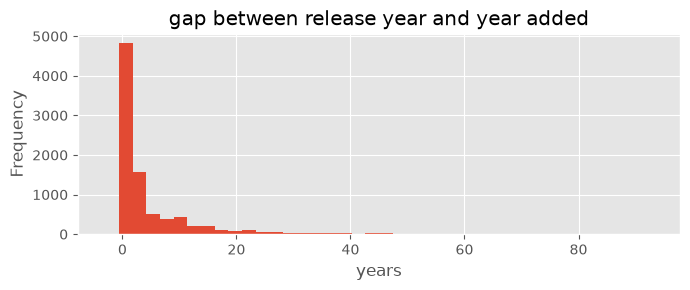

In [23]:
# content age summary and histogram
gap = (netflix["year_added"] - netflix["release_year"]).dropna()
print("content age summary:")
print(gap.describe().round(2))
print("negative gaps (added before release year):", (gap < 0).sum())
gap.plot(kind="hist", bins=40, figsize=(7, 3), title="gap between release year and year added")
plt.xlabel("years")
plt.tight_layout()
plt.show()

question 3 which countries and genres are most prominent

united states dominates, followed by india, united kingdom, and canada.
international movies and dramas are largest genre tags.
genre profiles differ among top countries.
india is more strongly linked with international movies.
united states has broader mix.

In [24]:
# top country and genre token lists
country_top = netflix["country"].str.split(",").explode().str.strip().value_counts().head(10)
print("top countries:")
print(country_top)
genre_top = netflix["listed_in"].str.split(",").explode().str.strip().value_counts().head(10)
print("\ntop genres:")
print(genre_top)

top countries:
country
United States     3690
India             1046
Unknown            831
United Kingdom     806
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Name: count, dtype: int64

top genres:
listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


question 4 how are maturity ratings distributed

tv ma and tv 14 are most common.
movies and tv shows have different rating patterns.
tv shows have more tv ma and tv 14.
movies have more r and pg 13.
rating patterns change a bit by year, but basic shape stays similar.

In [25]:
# rating distribution and last added years
print("rating distribution:")
print(netflix["rating"].value_counts().head(12))
rating_year = pd.crosstab(netflix["year_added"], netflix["rating"])
print("\nrating counts for last 3 added years:")
display(rating_year.tail(3))

rating distribution:
rating
TV-MA      3207
TV-14      2160
TV-PG       863
R           799
PG-13       490
TV-Y7       334
TV-Y        307
PG          287
TV-G        220
NR           80
G            41
Unknown       7
Name: count, dtype: int64

rating counts for last 3 added years:


rating,G,NC-17,NR,PG,PG-13,R,TV-14,TV-G,TV-MA,TV-PG,TV-Y,TV-Y7,TV-Y7-FV,UR,Unknown
year_added,,,,,,,,,,,,,,,
2019.0,8,1,4,81,135,208,494,40,736,198,54,54,1,2,0
2020.0,9,0,0,86,122,188,439,61,671,146,102,55,0,0,0
2021.0,4,0,0,58,146,190,326,44,489,97,57,87,0,0,0


extra evidence for question 4, movie and tv rating differences

rating,G,NC-17,NR,PG,PG-13,R,TV-14,TV-G,TV-MA,TV-PG,TV-Y,TV-Y7,TV-Y7-FV,UR,Unknown
type,,,,,,,,,,,,,,,
Movie,41,3,75,287,490,797,1427,126,2062,540,131,139,5,3,5
TV Show,0,0,5,0,0,2,733,94,1145,323,176,195,1,0,2


rating,G,NC-17,NR,PG,PG-13,R,TV-14,TV-G,TV-MA,TV-PG,TV-Y,TV-Y7,TV-Y7-FV,UR,Unknown
type,,,,,,,,,,,,,,,
Movie,0.7,0.0,1.2,4.7,8.0,13.0,23.3,2.1,33.6,8.8,2.1,2.3,0.1,0.0,0.1
TV Show,0.0,0.0,0.2,0.0,0.0,0.1,27.4,3.5,42.8,12.1,6.6,7.3,0.0,0.0,0.1


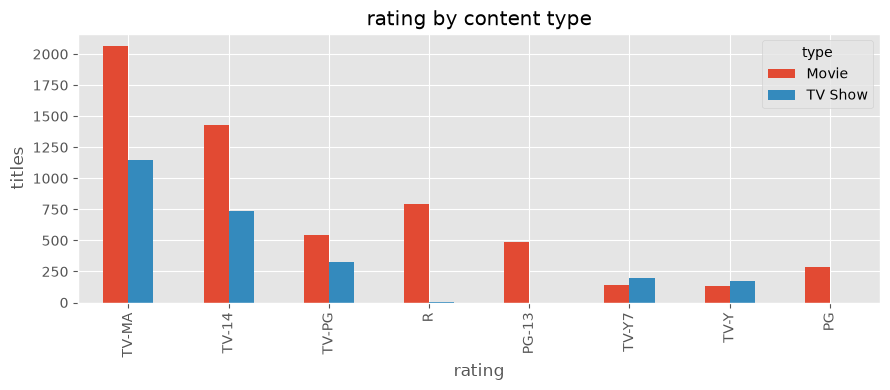

In [26]:
# cross table of type vs rating for question 4
rating_type_q4 = pd.crosstab(netflix["type"], netflix["rating"])
display(rating_type_q4)

# percent of each rating within each type
rating_type_q4_pct = rating_type_q4.div(rating_type_q4.sum(axis=1), axis=0) * 100
display(rating_type_q4_pct.round(1))

# top ratings chart by type
top_r = netflix["rating"].value_counts().head(8).index
rating_type_q4[top_r].T.plot(kind="bar", figsize=(9, 4), title="rating by content type")
plt.ylabel("titles")
plt.tight_layout()
plt.show()

question 5 movie durations and tv season counts

movie lengths centre around 90 to 100 minutes.
outliars include very short specials and 300 minute films.
tv shows are mostly one season.
few have many seasons.
i retained unusual cases because valid catalog entries, not bad data.

In [27]:
# unusual movie and show cases
print("movie minutes outliars top 10 longest:")
display(movie_only.nlargest(10, "movie_minutes")[["title", "release_year", "movie_minutes"]])
print("\nshortest movies:")
display(movie_only.nsmallest(10, "movie_minutes")[["title", "release_year", "movie_minutes"]])
print("\ntv shows with 10 plus seasons:")
display(tv_only[tv_only["season_count"] >= 10][["title", "release_year", "season_count"]])

movie minutes outliars top 10 longest:


,title,release_year,movie_minutes
4253,Black Mirror: Bandersnatch,2018,312.0
717,Headspace: Unwind Your Mind,2021,273.0
2491,The School of Mischief,1973,253.0
2487,No Longer kids,1979,237.0
2484,Lock Your Girls In,1982,233.0
2488,Raya and Sakina,1984,230.0
166,Once Upon a Time in America,1984,229.0
7932,Sangam,1964,228.0
1019,Lagaan,2001,224.0
4573,Jodhaa Akbar,2008,214.0



shortest movies:


,title,release_year,movie_minutes
3777,Silent,2014,3.0
2713,Sol Levante,2020,5.0
1484,Cops and Robbers,2020,8.0
1557,Canvas,2020,9.0
3535,American Factory: A Conversation with the Obamas,2019,10.0
2858,Calico Critters: Everyone's Big Dream Flying i...,2019,11.0
6405,Calico Critters: A Town of Dreams,2017,11.0
695,Besieged Bread,2015,12.0
3775,Cosmos Laundromat: First Cycle,2015,12.0
4707,Zion,2018,12.0



tv shows with 10 plus seasons:


,title,release_year,season_count
390,The Walking Dead,2019,10.0
548,Grey's Anatomy,2020,17.0
1354,Heartland,2019,13.0
1622,Stargate SG-1,2006,10.0
1759,LEGO Ninjago: Masters of Spinjitzu,2019,10.0
2203,Shameless (U.S.),2019,10.0
2423,Supernatural,2019,15.0
4220,COMEDIANS of the world,2019,13.0
4798,NCIS,2017,15.0
4964,Trailer Park Boys,2018,12.0


## a8 insights and handoff

five meaningful insights.

1 movies are about 69.6 percent of titles (6131 of 8807), so catalog is movie heavy but tv shows are large minority.

2 about 30 percent titles missing director (2634 of 8807), and mostly tv show related.

3 country cast listed_in are multi valued.
some titles list up to 12 countries or 3 genres in one cell.
counting tokens is more honest than counting rows.

4 gap between release year and year added has median of 1 year.
maximum about 93 years.
so netflix mixes fresh releases with old library titles.

5 movie durations roughly centre near 98 minutes.
most tv shows have only one season.
short movies and one 17 season show are valid but unusual.

speculation label: data cannot explain why added mix shifted toward tv shows after 2018.

handoff note for assignment 3

most informative variables are type, release_year, year_added, country tokens, listed_in tokens, rating, movie_minutes, and season_count.
num_countries and num_genres are useful summaries but partly overlap with exploded encodings.
content_age overlaps with release_year and year_added, so avoid using all three unchecked.
director and cast should not be treated as ordinary categories because sparse and high cardinality.
description and title are text, not direct features unless nlp used.
misplaced rating values were corrected.
three ratings became unknown.
missing director, cast, and country were filled unknown.
dates with no date_added remain missing.
keep show_id as identifier only.